# Classification de scanners thoraciques (COVID-19) avec un CNN

**Objectif** : entraîner un réseau de neurones convolutif (CNN) avec TensorFlow/Keras
qui classe une coupe de scanner thoracique (CT) dans l'une de ces 3 classes :

| Classe | Signification | Nombre d'images |
|--------|---------------|-----------------|
| `nCT`  | Poumons normaux | 9 979 |
| `pCT`  | Signes typiques du COVID-19 | 4 001 |
| `NiCT` | Coupe non informative (poumons non visibles) | 5 705 |

**Données** : dataset Kaggle *CT Scans for COVID-19 Classification* (azaemon),
images originales.

**Démarche** : on construit d'abord un petit CNN from scratch, puis on le comparera
à du transfer learning (MobileNetV3).

> Projet d'apprentissage. Ce n'est pas un outil médical et il ne doit pas
> servir à prendre des décisions de santé.

## 1. Vérification du GPU

L'entraînement d'un CNN demande beaucoup de calculs. Sur Google Colab, on active
un GPU (Exécution > Modifier le type d'exécution > T4 GPU) pour l'accélérer.

Cette cellule demande à TensorFlow la liste des GPU qu'il détecte.
- Si elle affiche un `PhysicalDevice(... 'GPU' ...)`, le GPU est actif.
- Si elle affiche `[]`, il n'est pas activé et l'entraînement sera très lent.

In [1]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))  # doit afficher un GPU, pas []

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Téléchargement du dataset

La bibliothèque `kagglehub` télécharge le dataset depuis Kaggle directement dans
l'environnement Colab, sans passer par l'ordinateur local.

La fonction renvoie `path`, le chemin du dossier où les fichiers ont été stockés.
Les cellules suivantes utiliseront cette variable.

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("azaemon/preprocessed-ct-scans-for-covid19")

print("Path to dataset files:", path)

100%|██████████| 3.59G/3.59G [00:40<00:00, 95.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/azaemon/preprocessed-ct-scans-for-covid19/versions/2


## 3. Exploration de la structure du dataset

Le dataset contient plusieurs sous-dossiers. Cette cellule les parcourt avec
`os.walk` pour repérer ceux qui contiennent les dossiers de classes
(`nCT`, `pCT`, `NiCT`) et compter les images de chacun.

On découvre deux versions des images : `Original CT Scans` et
`Preprocessed CT scans`, avec les mêmes effectifs par classe.
Nous utilisons les images **originales**.

La cellule ne modifie rien : elle lit seulement le contenu des dossiers.

In [5]:
import os

#1. ou sont les dossiers de classes ?
for root , dirs , files in os.walk(path):
  if any(c in dirs for c in ["nCT", "pCT", "NiCT"]):
    print("dossier parent:",root)
    for c in ["nCT", "pCT", "NiCT"]:
      if c in dirs:
        n= len(os.listdir(os.path.join(root,c)))
        print(f"{c}: {n} image")
  print()


dossier parent: /root/.cache/kagglehub/datasets/azaemon/preprocessed-ct-scans-for-covid19/versions/2/Original CT Scans
nCT: 9979 image
pCT: 4001 image
NiCT: 5705 image




dossier parent: /root/.cache/kagglehub/datasets/azaemon/preprocessed-ct-scans-for-covid19/versions/2/Preprocessed CT scans
nCT: 9979 image
pCT: 4001 image
NiCT: 5705 image






## 4. Préparation des données

**Étape 1 : lister les images.** On parcourt les 3 dossiers de classes et on
associe chaque fichier à un label entier : `nCT` = 0, `pCT` = 1, `NiCT` = 2.

**Étape 2 : séparer en trois jeux** avec `train_test_split` :
- **Train (70 %)** : le modèle apprend dessus.
- **Validation (15 %)** : on suit la progression pendant l'entraînement.
- **Test (15 %)** : évaluation finale, jamais vue pendant l'entraînement.

Deux paramètres importants :
- `stratify` : chaque jeu garde la même proportion de classes que le dataset complet.
- `random_state=42` : le découpage est identique à chaque exécution, donc les
  résultats sont reproductibles.

**Étape 3 : construire le pipeline `tf.data`.** Pour chaque image, la fonction
`load` la lit, la décode en 3 canaux (RGB) et la redimensionne en 224x224.
Les images sont ensuite regroupées par lots de 32 (`batch`) et préchargées
(`prefetch`) pour que le GPU n'attende pas les données. Seul le jeu d'entraînement
est mélangé (`shuffle`).

**Limite connue** : le découpage se fait par image et non par patient. Des coupes
très proches d'un même patient peuvent se retrouver dans train et test, donc le
score de test est probablement un peu optimiste.

In [8]:
import os, numpy as np, tensorflow as tf
from sklearn.model_selection import train_test_split

DATA_DIR = "/root/.cache/kagglehub/datasets/azaemon/preprocessed-ct-scans-for-covid19/versions/2/Original CT Scans"
CLASSES = ["nCT", "pCT", "NiCT"]
IMG_SIZE, BATCH = 224, 32

# 1. lister tous les fichiers + leur label (0, 1, 2)
paths, labels = [], []
for idx, c in enumerate(CLASSES):
    folder = os.path.join(DATA_DIR, c)
    for f in os.listdir(folder):
        paths.append(os.path.join(folder, f))
        labels.append(idx)
paths, labels = np.array(paths), np.array(labels)

# 2. split stratifié 70 / 15 / 15 (même proportion de classes partout)
p_train, p_tmp, y_train, y_tmp = train_test_split(
    paths, labels, test_size=0.30, stratify=labels, random_state=42)
p_val, p_test, y_val, y_test = train_test_split(
    p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)
print("train / val / test :", len(p_train), len(p_val), len(p_test))

# 3. lecture + redimensionnement des images
def load(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

def make_ds(p, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((p, y))
    if shuffle:
        ds = ds.shuffle(len(p), seed=42)
    return ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(p_train, y_train, shuffle=True)
val_ds   = make_ds(p_val, y_val)
test_ds  = make_ds(p_test, y_test)

train / val / test : 13779 2953 2953


## 5. Vérification visuelle

On affiche 8 images d'un lot d'entraînement avec leur classe. Cela permet de
vérifier que les images sont bien lues et que les labels correspondent à ce qu'on voit.

Les pixels sont convertis en `uint8` (entiers de 0 à 255) uniquement pour
l'affichage avec `matplotlib`.

<function matplotlib.pyplot.show(close=None, block=None)>

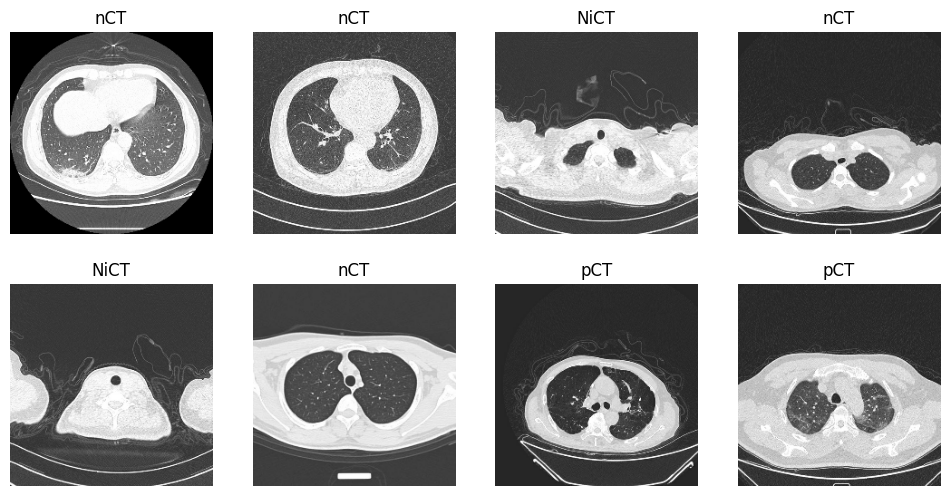

In [11]:
import matplotlib.pyplot as plt

imgs ,labs = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
  plt.subplot(2,4,i+1)
  plt.imshow(imgs[i].numpy().astype("uint8"))
  plt.title(CLASSES[labs[i]])
  plt.axis("off")
plt.show

## 6. Architecture du CNN

Un CNN apprend à reconnaître des motifs visuels, des plus simples aux plus complexes.

| Couche | Rôle |
|--------|------|
| `RandomFlip` | Retourne aléatoirement l'image à l'horizontale pendant l'entraînement (augmentation de données). Inactif à l'évaluation. |
| `Rescaling(1/255)` | Ramène les pixels de 0-255 à 0-1, ce qui facilite l'apprentissage. |
| `Conv2D` | Applique des filtres qui détectent des motifs (bords, textures...). 32, puis 64, puis 128 filtres : plus on avance, plus les motifs sont complexes. |
| `MaxPooling2D` | Réduit la taille de l'image de moitié (224 > 112 > 56 > 28) en gardant les valeurs les plus fortes. |
| `GlobalAveragePooling2D` | Résume chaque carte de features par sa moyenne : on obtient un vecteur de 128 valeurs. |
| `Dense(128)` | Couche entièrement connectée qui combine ces valeurs. |
| `Dropout(0.3)` | Désactive 30 % des neurones au hasard pendant l'entraînement pour limiter le surapprentissage. |
| `Dense(3, softmax)` | Sortie : une probabilité par classe, la somme valant 1. |

**Compilation :**
- `optimizer="adam"` : algorithme qui ajuste les poids du réseau.
- `loss="sparse_categorical_crossentropy"` : mesure l'erreur pour une classification
  multi-classes avec des labels entiers (0, 1, 2).
- `metrics=["accuracy"]` : proportion d'images bien classées.

Le modèle compte environ 110 000 paramètres : c'est un réseau très léger.

In [19]:
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input((224, 224 ,3)),
    layers.RandomFlip("horizontal"),
    layers.Rescaling(1/255),

    layers.Conv2D(32,3, padding="same" ,activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64,3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128,activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax"),
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_3 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,147 (430.26 KB)

 Trainable params: 110,147 (430.26 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Entraînement

`model.fit` entraîne le réseau pendant 10 epochs. Une epoch correspond à un passage
complet sur toutes les images d'entraînement.

À chaque epoch, deux mesures sont affichées :
- `accuracy` et `loss` : sur les données d'entraînement ;
- `val_accuracy` et `val_loss` : sur les données de validation, jamais utilisées
  pour apprendre.

**Comment lire les résultats :**
- Les deux accuracies montent : le modèle apprend bien.
- `accuracy` monte mais `val_accuracy` stagne ou baisse : surapprentissage.
- Aucune des deux ne bouge : le modèle n'apprend pas.

L'objet `history` conserve ces courbes pour les tracer ensuite.

In [20]:
history = model.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10
431/431 ━━━━━━━━━━━━━━━━━━━━ 90s 180ms/step - accuracy: 0.6297 - loss: 0.7837 - val_accuracy: 0.7172 - val_loss: 0.5668
Epoch 2/10
431/431 ━━━━━━━━━━━━━━━━━━━━ 50s 115ms/step - accuracy: 0.7774 - loss: 0.4854 - val_accuracy: 0.8463 - val_loss: 0.3579
Epoch 3/10
431/431 ━━━━━━━━━━━━━━━━━━━━ 80s 110ms/step - accuracy: 0.8463 - loss: 0.3638 - val_accuracy: 0.8463 - val_loss: 0.3353
Epoch 4/10
431/431 ━━━━━━━━━━━━━━━━━━━━ 50s 115ms/step - accuracy: 0.8813 - loss: 0.2978 - val_accuracy: 0.9092 - val_loss: 0.2328
Epoch 5/10
431/431 ━━━━━━━━━━━━━━━━━━━━ 50s 115ms/step - accuracy: 0.9044 - loss: 0.2501 - val_accuracy: 0.9269 - val_loss: 0.1951
Epoch 6/10
431/431 ━━━━━━━━━━━━━━━━━━━━ 47s 110ms/step - accuracy: 0.9275 - loss: 0.1991 - val_accuracy: 0.9194 - val_loss: 0.1935
Epoch 7/10
431/431 ━━━━━━━━━━━━━━━━━━━━ 48s 110ms/step - accuracy: 0.9416 - loss: 0.1684 - val_accuracy: 0.9333 - val_loss: 0.1659
Epoch 8/10
431/431 ━━━━━━━━━━━━━━━━━━━━ 50s 115ms/step - accuracy: 0.9450 - loss: 0

###8 : courbes + évaluation sur le test

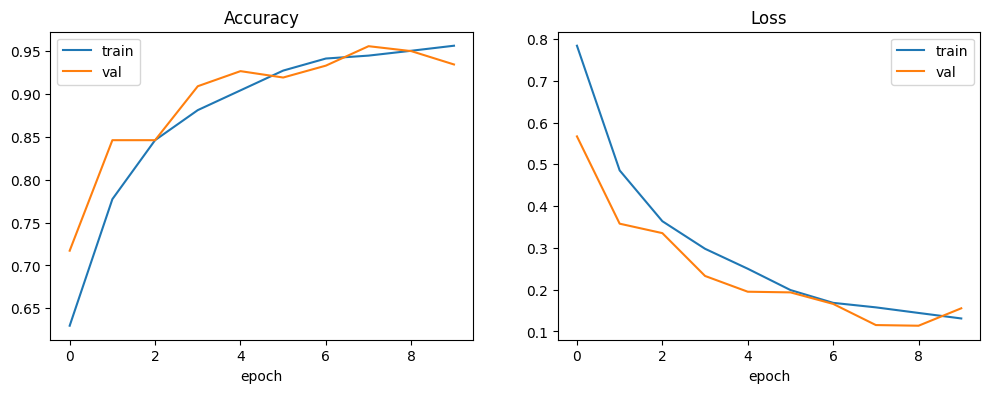

93/93 ━━━━━━━━━━━━━━━━━━━━ 13s 140ms/step - accuracy: 0.9374 - loss: 0.1564
Test accuracy : 0.9374
93/93 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step
              precision    recall  f1-score   support

         nCT       0.90      0.99      0.95      1497
         pCT       0.98      0.77      0.86       600
        NiCT       0.98      0.95      0.97       856

    accuracy                           0.94      2953
   macro avg       0.95      0.91      0.93      2953
weighted avg       0.94      0.94      0.94      2953



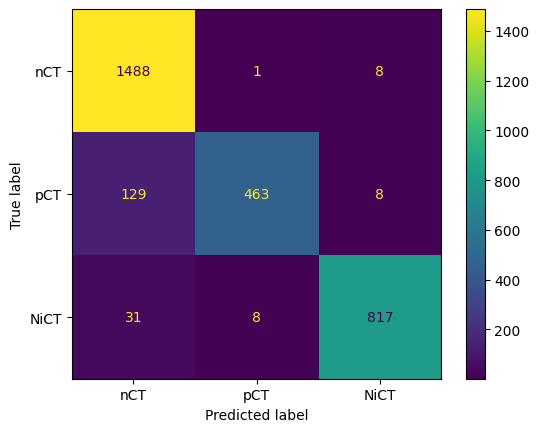

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. courbes d'apprentissage
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

# 2. évaluation finale sur le jeu de test (jamais vu)
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy : {test_acc:.4f}")

# 3. prédictions détaillées par classe
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_test, y_pred, target_names=CLASSES))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=CLASSES).plot()
plt.show()

# 4. sauvegarde du modèle
model.save("cnn_scratch.keras")

### 9: Les graphes utile pour La presentatation du projet

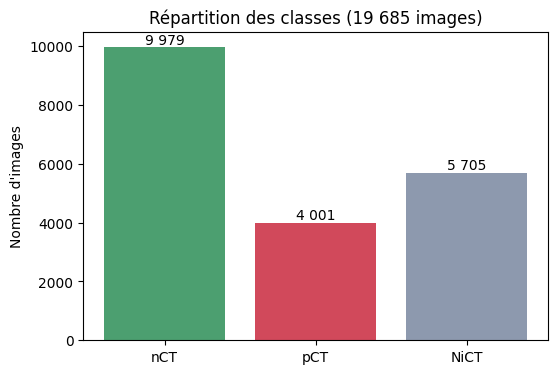

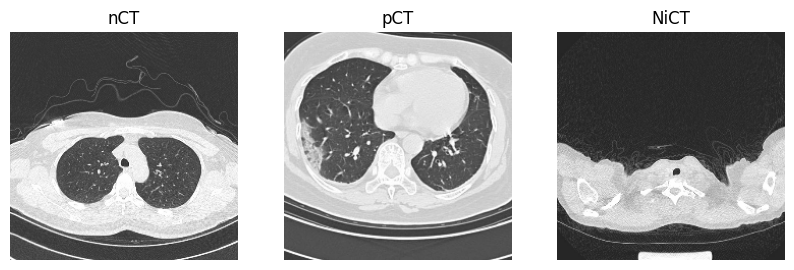

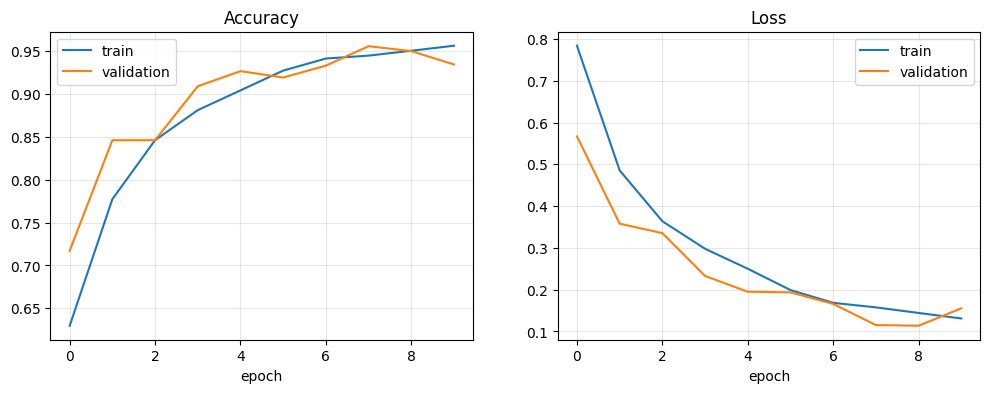

93/93 ━━━━━━━━━━━━━━━━━━━━ 13s 140ms/step


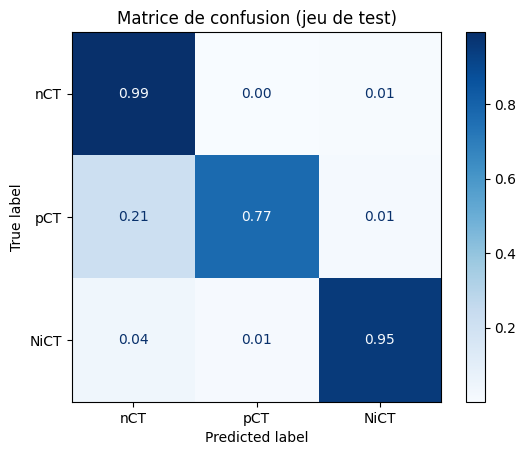

              precision    recall  f1-score   support

         nCT      0.903     0.994     0.946      1497
         pCT      0.981     0.772     0.864       600
        NiCT      0.981     0.954     0.967       856

    accuracy                          0.937      2953
   macro avg      0.955     0.907     0.926      2953
weighted avg      0.941     0.937     0.936      2953



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# ===== Cellule Colab : génère les graphes du README =====
# À lancer APRÈS l'entraînement (il faut : history, model, train_ds, test_ds,
# y_train, y_val, y_test). Adapte les noms si tes variables sont différentes.

import os, shutil
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

CLASSES = ["nCT", "pCT", "NiCT"]
COLORS = ["#4C9F70", "#D1495B", "#8D99AE"]
os.makedirs("assets", exist_ok=True)

# 1. Répartition des classes
counts = np.bincount(np.concatenate([y_train, y_val, y_test]))
plt.figure(figsize=(6, 4))
bars = plt.bar(CLASSES, counts, color=COLORS)
for b, c in zip(bars, counts):
    plt.text(b.get_x() + b.get_width() / 2, c + 100, f"{c:,}".replace(",", " "), ha="center")
plt.title("Répartition des classes (19 685 images)")
plt.ylabel("Nombre d'images")
plt.savefig("assets/class-distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Une image par classe
found = {}
for imgs, labs in train_ds:
    for img, lab in zip(imgs, labs.numpy()):
        found.setdefault(int(lab), img.numpy().astype("uint8"))
    if len(found) == 3:
        break
plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(found[i])
    plt.title(CLASSES[i])
    plt.axis("off")
plt.savefig("assets/ct-examples.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Courbes d'apprentissage
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy")
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss")
for a in ax:
    a.set_xlabel("epoch")
    a.legend()
    a.grid(alpha=0.3)
plt.savefig("assets/training-curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 4. Matrice de confusion (normalisée par ligne) + rapport par classe
y_pred = np.argmax(model.predict(test_ds), axis=1)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=CLASSES,
    normalize="true", cmap="Blues", values_format=".2f")
plt.title("Matrice de confusion (jeu de test)")
plt.savefig("assets/confusion-matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# Copie ces valeurs dans le tableau "Résultats par classe" du README
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

# 5. Zip des graphes + téléchargement
shutil.make_archive("assets", "zip", "assets")
from google.colab import files
files.download("assets.zip")